# 08 · Motif sites across mammals (Fig 5A)

For every mouse pdCRE with a one-to-one ortholog, the energy of its strongest Mesp2 site and of the sites of its orthologs
in 30 other mammals, in bins of the mouse percentiles (90th, 94th, 97th), and the evolutionary class of the site: gained in
*Mus* (mus), conserved in rodents (fam), conserved across mammals (pan), or other patterns; Fig 5A shows the pdCREs of CRECl
6.1 (mouse k-means CRECl 90), with ten more lagomorphs.

1. **Classes** (the 'evolutionary classes' of the Methods): rule classes for strong sites (mus, pan; mmus, mpan for medium
   ones), k-means (k = 10, seed 1) of the rest by clade, the clusters named by their clade pattern, and the 'fam' rule.
2. **Lagomorph rows**: ten more lagomorphs and the re-lifted snowhare.
3. **Fig 5A**: the 412 pdCREs of CRECl 6.1 by class, over the species tree.

## Setup

In [1]:
source("../R/setup.R")
suppressMessages({library(data.table); library(ape); library(bnpsd); library(patchwork); library(grid)})  # data.table last
silhouettes = c("mm", "rat", "ory", "cr", "jerb", "dipo", "fr", "fr2", "le", "och", "ph", "hs")
O1 = file.path(OUT_DIR, "01_crecls")
O4 = file.path(OUT_DIR, "04_motifs")
O5 = file.path(OUT_DIR, "05_orthology")
MOTIF = "Mesp2"
IN = list(specsf = data_path("specsf.csv"), specsff = data_path("specsff.old.csv"), tree = data_path("species_tree_241_lago.nwk"))
silhouette = function(name) data_path(paste0("silhouette_", name, ".png"))
# the motif energies at the orthologs of each species, from the slim exports (one gzipped CSV per direction)
slim = list()
energies_of = function(dir, sp) {
    if (is.null(slim[[dir]])) slim[[dir]] <<- fread(data_path(sprintf("%s2species_energies.csv.gz", dir)), select = c("species", "cre_id", selected_motifs))
    slim[[dir]][species == sp, c("cre_id", selected_motifs), with = FALSE]
}

## 1. Classes

Inputs: CRECls (notebook 01), CRECl enrichment (notebook 04), the ortholog table (notebook 05) and the motif energies of the
mouse and rabbit loci.

In [2]:
N_NB_MOTIFS <- 21
selected_motifs <- MOTIF
# ---- CRECls, enrichment, orthologs ----
mm_crecl = fread(file.path(O1, "mm_crecl.csv")); oc_crecl = fread(file.path(O1, "oc_crecl.csv"))
mm_km = as.character(mm_crecl$kmc); names(mm_km) = mm_crecl$locid
oc_km = as.character(oc_crecl$kmc); names(oc_km) = oc_crecl$locid
mm = fread(data_path("mm_emb_locif.csv")) %>% left_join(fread(data_path("mm_namespace_2025.csv")), by = join_by(chrom, start, end))
mm_enrich_df = fread(file.path(O4, "mm_enrich_df.csv")); oc_enrich_df = fread(file.path(O4, "oc_enrich_df.csv"))
mm_intervals = fread(data_path("mm_namespace_2025.csv"))
oc_intervals = fread(data_path("oc_namespace_2025.csv")) %>% filter(end-start == 500)
orth_full = fread(file.path(O5, "orth_full_wmode_wgotg.csv"))
# ---- the CRECls of both loci of each ortholog row ----
orth_full_stranded_condensed = orth_full %>% left_join(
        tibble::enframe(mm_km) %>% rename(mm_locid=name, mm_km=value), by="mm_locid") %>% left_join(
        tibble::enframe(oc_km) %>% rename(oc_locid=name, oc_km=value), by="oc_locid")
# ---- mouse pdCREs with complete motif energies ----
mm_energies_full = fread(data_path("mm_energies_raw_2025.csv"))
oc_energies_full = fread(data_path("oc_energies_raw_2025.csv"))
mmef = mm_energies_full %>% select(-chrom, -start, -end) %>% column_to_rownames("mm_locid")
mm_notss = mm %>% filter(mm_locid %in% rownames(mmef[rowSums(is.na(mmef)) == 0, ]))

In [3]:
# ---- mouse percentile thresholds (q90 / q94 / q97) ----
mm_energies_mm_km = mmef[intersect(names(mm_km), rownames(mmef[mm_notss$mm_locid,])),]
mm_e_thresholds90 = apply(mm_energies_mm_km,2,function(x){quantile(x, 0.90)})
mm_e_thresholds94 = apply(mm_energies_mm_km,2,function(x){quantile(x, 0.94)})
mm_e_thresholds97 = apply(mm_energies_mm_km,2,function(x){quantile(x, 0.97)})

In [4]:
# ---- motif energies of both loci ----
all_loc_e_orth_km = orth_full_stranded_condensed %>% full_join(
    mm_energies_full %>% select(mm_locid, all_of(selected_motifs)), by="mm_locid", relationship = "many-to-many") %>% full_join(
    oc_energies_full %>% select(oc_locid, all_of(selected_motifs)), by="oc_locid", relationship = "many-to-many", suffix = c("_mm", "_oc")) %>% distinct()
stopifnot(all(paste0(selected_motifs, c("_mm", "_oc")) %in% names(all_loc_e_orth_km)))

In [5]:
# ---- the 30 other mammals; their energies at the orthologs of peaks with one image ----
rename_v = fread(IN$specsf) %>% select(GenomeName, name) %>% tibble::deframe()
SPS <- c("Mus_spretus","Mus_caroli","Mus_pahari","Rattus_norvegicus","Acomys_cahirinus","Psammomys_obesus","Microtus_ochrogaster","Ellobius_lutescens",
         "Cricetulus_griseus","Peromyscus_maniculatus","Jaculus_jaculus","Dipodomys_ordii","Ictidomys_tridecemlineatus","Marmota_marmota","Meriones_unguiculatus",
         "Cricetomys_gambianus","Ellobius_talpinus","Ondatra_zibethicus","Allactaga_bullata","Zapus_hudsonius","Dipodomys_stephensi","Xerus_inauris",
         "Spermophilus_dauricus","Muscardinus_avellanarius","Graphiurus_murinus","Glis_glis","Lepus_americanus","Homo_sapiens","Gorilla_gorilla","Pongo_abelii")
rename_v["Homo_sapiens"] <- "human"
stopifnot(!anyNA(rename_v[SPS]))
uniq_renamed <- function(dir, sp, key) {
	x <- energies_of(dir, sp)
	x <- x %>% filter(cre_id %in% (x %>% group_by(cre_id) %>% summarise(c=n()) %>% filter(c==1) %>% pull(cre_id)))
	x %>% rename(!!key := cre_id) %>% select(all_of(c(key, selected_motifs))) %>% rename_with(~paste0(.x, "_", rename_v[sp]), all_of(selected_motifs)) }
# ---- energy bins of each peak and its orthologs ----
long_tab <- function(ekm, dir, key, totcol) {
	w <- ekm %>% filter(.data[[totcol]] == 1)
	for (sp in SPS) w <- w %>% left_join(uniq_renamed(dir, sp, key), by = key)
	w %>% filter(imgstat != "NA") %>%
		select(mm_locid, imgstat, mm_km, oc_km, oc_locid, paste0(selected_motifs, "_mm"), paste0(selected_motifs, "_oc"), all_of(unlist(lapply(SPS, function(sp) paste0(selected_motifs, "_", rename_v[sp]))))) %>%
		pivot_longer(!c(mm_locid, imgstat, mm_km, oc_km, oc_locid), names_to = "motif_spec", values_to = "e") %>%
		separate_wider_regex(motif_spec, c(motif = ".*?", "_", spec = ".*$")) %>%
		mutate(bin = 0+(e > mm_e_thresholds90[motif])+(e > mm_e_thresholds94[motif])+(e > mm_e_thresholds97[motif])) %>%
		left_join(mm_enrich_df %>% filter(motif %in% selected_motifs) %>% mutate(mm_km=as.character(crecl)) %>% select(mm_km, motif, mm_enrich=enrich)) %>%
		left_join(oc_enrich_df %>% filter(motif %in% selected_motifs) %>% mutate(oc_km=as.character(crecl)) %>% select(oc_km, motif, oc_enrich=enrich)) }
mm2oc_ekm = all_loc_e_orth_km %>% filter(!is.na(mm_km)) %>% filter(!is.na(mm_peak_id)) %>% mutate(imgstat=mm_mode)
oc2mm_ekm = all_loc_e_orth_km %>% filter(!is.na(oc_km)) %>% filter(!is.na(oc_peak_id)) %>% mutate(imgstat=mm_mode)
mm2oc_long = long_tab(mm2oc_ekm, "mm", "mm_peak_id", "mm_orth_tot")
oc2mm_long = long_tab(oc2mm_ekm, "oc", "oc_peak_id", "oc_orth_tot")

Joining with `by = join_by(mm_km, motif)`


Joining with `by = join_by(oc_km, motif)`


Joining with `by = join_by(mm_km, motif)`


Joining with `by = join_by(oc_km, motif)`


In [6]:
# ---- both directions without duplicates; species order and clade groups ----
dups = c(intersect(mm2oc_long$mm_locid, oc2mm_long$mm_locid), names(which(table(oc2mm_long$mm_locid) > 700 / N_NB_MOTIFS)))
mm2oc_longer = rbind(mm2oc_long, oc2mm_long %>% filter(!mm_locid %in% dups))
mm2oc_longer = mm2oc_longer %>% filter(!imgstat %in% c("ctcf", "p2l"))
ord_specs = fread(IN$specsff) %>% pull(name)
spec_groups = c(fread(IN$specsff) %>% select(name, group) %>% tibble::deframe())
ord_groups = c("mm", "mus", 'rat', 'om', "cr", "jerb", "dipo", "fr", "fr2", "lago", "ph")

In [7]:
# ---- the classifier ----
km_ord = 1:19
names(km_ord) = c('mus', 'pan', "single-clade", "single", "None", 'mus-km', "mus-med-km", "mus/rat-km", "mus/rat-med-km", "cr-km", "cr-med-km", 'pan-km', 'pan-med-km', 'pan-weak-km', "single-clade-km")
    motif_evo_long = as.data.frame(mm2oc_longer %>% filter(imgstat %in% c("p2p", "p2w", "p2b")) %>%
        select(mm_locid, imgstat, motif, spec, e, bin, mm_enrich, oc_enrich) %>%
        filter(motif==MOTIF))
    motif_evo = motif_evo_long %>% select(-e) %>% pivot_wider(names_from = spec, values_from = bin)
    motif_evo_with_e = motif_evo_long %>% select(-bin) %>% pivot_wider(names_from = spec, values_from = e)
    motif_evo_mat = as.matrix((0 + motif_evo %>% select(-imgstat, -motif, -mm_enrich, -oc_enrich) %>% column_to_rownames("mm_locid"))[,ord_specs])
    motif_evo_mat_e = as.matrix((0 + motif_evo_with_e %>% select(-imgstat, -motif, -mm_enrich, -oc_enrich) %>% column_to_rownames("mm_locid"))[,ord_specs])
    motif_evo_mat_zeros = motif_evo_mat[rowSums(motif_evo_mat>1, na.rm=T)==0,]
    motif_evo_mat_non_zero = motif_evo_mat[rowSums(motif_evo_mat>1, na.rm=T)>0,]
    motif_evo_mat_e_zeros = motif_evo_mat_e[rowSums(motif_evo_mat>1, na.rm=T)==0,]
    motif_evo_mat_e_non_zero = motif_evo_mat_e[rowSums(motif_evo_mat>1, na.rm=T)>0,]
    motif_evo_mat_multi_sg = suppressWarnings(t(col_group_apply(motif_evo_mat_non_zero, spec_groups[colnames(motif_evo_mat_non_zero)], function(v) max(v, na.rm=TRUE))))
    motif_evo_mat_multi_sg[motif_evo_mat_multi_sg==-Inf] = NA
    motif_evo_mat_e_multi_sg = suppressWarnings(t(col_group_apply(motif_evo_mat_e_non_zero, spec_groups[colnames(motif_evo_mat_e_non_zero)], function(v) max(v, na.rm=TRUE))))
    motif_evo_mat_e_multi_sg[motif_evo_mat_e_multi_sg==-Inf] = NA
    sg_strong_f = motif_evo_mat_multi_sg[,'mm'] > 2
    sg_strong_f[is.na(sg_strong_f)] = FALSE
    sg_pan_f = sg_strong_f & motif_evo_mat_non_zero[,"oc"] > 2
    sg_pan_f[is.na(sg_pan_f)] = FALSE
    sg_pan = motif_evo_mat_multi_sg[sg_pan_f,]
    sg_mus_f = !sg_pan_f & sg_strong_f & abs(apply(motif_evo_mat_multi_sg[,setdiff(colnames(motif_evo_mat_multi_sg), c("mm", "mus"))], 1, function(x){sort(-x)[2]})) <= 1
    sg_mus_f[is.na(sg_mus_f)] = FALSE
    sg_mus = motif_evo_mat_multi_sg[sg_mus_f,]
    sg_mpan_f = !sg_strong_f & (motif_evo_mat_multi_sg[,'mm'] > 1) & motif_evo_mat_non_zero[,"oc"] > 1
    sg_mpan_f[is.na(sg_mpan_f)] = FALSE
    sg_mpan = motif_evo_mat_multi_sg[sg_mpan_f,]
    sg_mmus_f = !sg_strong_f & !sg_mpan_f & (motif_evo_mat_multi_sg[,'mm'] > 1) & abs(apply(motif_evo_mat_multi_sg[,setdiff(colnames(motif_evo_mat_multi_sg), c("mm", "mus"))], 1, function(x){sort(-x)[2]})) <= 1
    sg_mmus_f[is.na(sg_mmus_f)] = FALSE
    sg_mmus = motif_evo_mat_multi_sg[sg_mmus_f,]
    motif_evo_mat_multi = motif_evo_mat_multi_sg[!(sg_pan_f | sg_mus_f | sg_mpan_f | sg_mmus_f),]
    sg4km_e = motif_evo_mat_e_multi_sg[rownames(motif_evo_mat_multi),]
    sg4km = motif_evo_mat_multi_sg[rownames(motif_evo_mat_multi),]
    k = 10
    evo_km = tglkmeans::TGL_kmeans(sg4km_e, k = k, seed=1, hclust_intra_clusters = FALSE)
    motif_evo = motif_evo %>% mutate(evo_km_name = as.character(evo_km$cluster[mm_locid]))
    grouped_grouped = col_group_apply(t(0+(sg4km>2)), evo_km$cluster, function(v){mean(v, na.rm=T)})
    grouped_grouped_m = col_group_apply(t(0+(sg4km>1)), evo_km$cluster, function(v){mean(v, na.rm=T)})
    km_annot = rep(NA, dim(grouped_grouped)[1])
    names(km_annot) = names(evo_km$size)
    km_annot[is.na(km_annot) & apply(grouped_grouped, 1, function(x){sort(x)[2]}) > 0.15] = "pan-km"
    km_annot[is.na(km_annot) & apply(grouped_grouped_m, 1, function(x){sort(x)[2]}) > 0.15] = "pan-med-km"
    km_annot[is.na(km_annot) & (grouped_grouped[,"mm"] >= 0.15 | grouped_grouped[,"mus"] >= 0.15) & abs(apply(grouped_grouped[,setdiff(colnames(grouped_grouped), c("mm", "mus"))], 1, function(x){sort(-x)[2]})) < 0.15] = "mus-km"
    km_annot[is.na(km_annot) & (grouped_grouped[,"mm"] >= 0.15 | grouped_grouped[,"mus"] >= 0.15) & grouped_grouped[,"rat"] >= 0.15 & abs(apply(grouped_grouped[,setdiff(colnames(grouped_grouped), c("mm", "mus", "rat"))], 1, function(x){sort(-x)[2]})) < 0.15] = "mus/rat-km"
    km_annot[is.na(km_annot) & (grouped_grouped_m[,"mm"] >= 0.15 | grouped_grouped_m[,"mus"] >= 0.15) & abs(apply(grouped_grouped_m[,setdiff(colnames(grouped_grouped), c("mm", "mus"))], 1, function(x){sort(-x)[2]})) < 0.15] = "mus-med-km"
    km_annot[is.na(km_annot) & (grouped_grouped_m[,"mm"] >= 0.15 | grouped_grouped_m[,"mus"] >= 0.15) & grouped_grouped_m[,"rat"] >= 0.15 & abs(apply(grouped_grouped_m[,setdiff(colnames(grouped_grouped), c("mm", "mus", "rat"))], 1, function(x){sort(-x)[2]})) < 0.15] = "mus/rat-med-km"
    km_annot[is.na(km_annot) & (grouped_grouped[,"mm"] >= 0.15 & grouped_grouped[,"mus"] >= 0.15) & grouped_grouped[,"cr"] >= 0.15 & abs(apply(grouped_grouped[,setdiff(colnames(grouped_grouped), c("mm", "mus", "rat","om", "cr"))], 1, function(x){sort(-x)[2]})) < 0.15] = "cr-km"
    km_annot[is.na(km_annot) & (grouped_grouped_m[,"mm"] >= 0.15 & grouped_grouped_m[,"mus"] >= 0.15) & grouped_grouped_m[,"cr"] >= 0.15 & abs(apply(grouped_grouped_m[,setdiff(colnames(grouped_grouped), c("mm", "mus", "rat", "om", "cr"))], 1, function(x){sort(-x)[2]})) < 0.15] = "cr-med-km"
    km_annot[is.na(km_annot) & rowSums(grouped_grouped>0.15, na.rm=T) < 3 & grouped_grouped[,'mm'] <= 0.15] = "single-clade-km"
    km_annot[is.na(km_annot)] = "zmus"
    km_annot = c(c('-4'="None"),  c('-3'="pan"), c('-2'="mus"), c('-1'="mpan"), c('0'="mmus"), km_annot)
    motif_evo = motif_evo %>% mutate(
        evo_km_name = ifelse(is.na(evo_km_name),
            ifelse(mm_locid %in% rownames(motif_evo_mat_zeros), '-4',
            ifelse(mm_locid %in% rownames(sg_pan), '-3',
            ifelse(mm_locid %in% rownames(sg_mus), '-2',
            ifelse(mm_locid %in% rownames(sg_mpan), '-1',
            ifelse(mm_locid %in% rownames(sg_mmus), '0', "strange"))))), evo_km_name)) %>% mutate(evo_km_annot = km_annot[evo_km_name])

In [8]:
# ---- the 'fam' rule: strong mouse sites of single-clade clusters ----
motif_evo = motif_evo %>% mutate(evo_km_name_nb = evo_km_name, evo_km_annot_nb = evo_km_annot)
sc_ids = names(km_annot)[km_annot == "single-clade-km"]
motif_evo = motif_evo %>% mutate(
    evo_km_name  = ifelse(evo_km_name %in% sc_ids & mm_locid %in% names(which(sg_strong_f)), "-5", evo_km_name),
    evo_km_annot = ifelse(evo_km_name == "-5", "fam", evo_km_annot))
R <- list(motif = MOTIF, motif_evo = motif_evo, mm2oc_long = mm2oc_long %>% filter(motif == MOTIF), evo_km = evo_km, km_annot = km_annot,
          grouped_grouped = grouped_grouped, grouped_grouped_m = grouped_grouped_m, sg4km = sg4km, sg4km_e = sg4km_e,
          thr = c(q90 = mm_e_thresholds90[[MOTIF]], q94 = mm_e_thresholds94[[MOTIF]], q97 = mm_e_thresholds97[[MOTIF]]))

## 2. Lagomorph rows

Per species, the strongest image of each CRECl-6.1 pdCRE, binned by the mouse thresholds.

In [9]:
# Ten more lagomorphs and the re-lifted snowhare: per species, the strongest image (max over images) of each CRECl-90 locus, binned by the
# mouse q90 / q94 / q97 (R$thr).
LX <- c("Lepus_capensis","Lepus_europaeus","Lepus_oiostolus","Lepus_timidus","Lepus_townsendii","Lepus_yarkandensis","Sylvilagus_floridanus","Sylvilagus_bachmani","Ochotona_princeps","Ochotona_curzoniae")
TQ <- R$thr
binm <- function(v) { b <- rep(NA_integer_, length(v)); ok <- !is.na(v); b[ok] <- 0L + (v[ok] > TQ[1]) + (v[ok] > TQ[2]) + (v[ok] > TQ[3]); b }
kmv <- setNames(as.character(mm_crecl$kmc), mm_crecl$locid)
loci90 <- mm %>% filter(kmv[mm_locid] %in% "90") %>% select(mm_locid, cre_id)
lago_slim <- fread(data_path("mm2lago_energies_cl90.csv"), select = c("species", "cre_id", MOTIF))
lago_energies <- function(s) lago_slim[species == s, c("cre_id", MOTIF), with = FALSE]
newrows <- rbindlist(lapply(c(LX, "Lepus_americanus"), function(s) {
	e <- lago_energies(s)[cre_id %in% loci90$cre_id][, lapply(.SD, max, na.rm = TRUE), by = cre_id, .SDcols = MOTIF]
	data.table(mm_locid = loci90$mm_locid, spec = if (s == "Lepus_americanus") "snowhare" else s, bin = binm(e[[MOTIF]][match(loci90$cre_id, e$cre_id)])) }))

## 3. Fig 5A

The panel at its print size (7 in wide), with the font and the off-screen text measurement of the October panels.

In [10]:
# the font, and an off-screen device to measure text with it
SUP_FONT <- "Nimbus Sans"
cairo_offscreen <- function(width, height) {
    grDevices::cairo_pdf(tempfile(fileext = ".pdf"), width = width, height = height, family = SUP_FONT)
    grDevices::dev.control("enable")
}

In [11]:
sp <- fread(IN$specsff); ord_specs <- sp$name
spec_groups <- setNames(sp$group, sp$name); ord_groups <- c("mm", "mus", "rat", "om", "cr", "jerb", "dipo", "fr", "fr2", "lago", "ph")
CRECL_LAB <- "6.1"
me <- as.data.frame(R$motif_evo)
# ---- column order: by class genome-wide, then within CRECl 90 ----
pp2p <- me %>% group_by(evo_km_name) %>% summarise(np2p = sum(imgstat %in% c("p2p", "p2w")), n = n()) %>% mutate(pp2p = np2p / n)
me <- me %>% left_join(pp2p, by = "evo_km_name")
mat_all <- as.matrix(me[, ord_specs]); rownames(mat_all) <- me$mm_locid
nz <- mat_all[rowSums(mat_all > 1, na.rm = TRUE) > 0, ]
sg <- suppressWarnings(t(col_group_apply(nz, spec_groups[colnames(nz)], function(v) max(v, na.rm = TRUE)))); sg[sg == -Inf] <- NA
gmax <- apply(sg[, ord_groups], 1, which.max)
km_gmax <- apply(R$grouped_grouped[, ord_groups], 1, which.max)
me <- me %>% arrange(km_ord[evo_km_annot], km_gmax[evo_km_name], evo_km_name, gmax[mm_locid], apply(mat_all, 1, which.max)[mm_locid])
man_reord = c('-2' = 1, '-3' = 5, '-4' = 7, '1' = 2, '4' = 3, '3' = 6, '2' = 6, '5' = 6, '7' = 6, '8' = 6, '10' = 6, '6' = 6, '-1' = 4, '0' = 0)
man_reord['9'] = 6
man_reord['-5'] = 2
c90 <- me %>% filter(kmv[mm_locid] == "90")
m90 <- as.matrix(c90[, ord_specs]); rownames(m90) <- c90$mm_locid
c90 <- c90 %>% arrange(man_reord[evo_km_name], apply(m90, 1, which.max)[mm_locid])
stopifnot(!anyDuplicated(c90$mm_locid))
newrows <- newrows[mm_locid %in% c90$mm_locid]
ev <- melt(as.data.table(c90)[, c("mm_locid", ord_specs), with = FALSE], id.vars = "mm_locid", variable.name = "spec", value.name = "bin", variable.factor = FALSE)
EM <- rbind(ev[spec != "snowhare"], newrows); stopifnot(nrow(EM) == 42 * nrow(c90))
LG <- c(oc = "oryc", snowhare = "lepus", setNames(c(rep("lepus", 6), "sylv", "sylv", "och", "och"), LX))
sp <- rbind(sp, data.table(GenomeName = LX, mus_ord = 33 + seq_along(LX) / 100, group = "lago", name = LX))
sp[name %in% names(LG), group := LG[name]]

In [12]:
# ---- species tree: the 241 Lago HAL tree (v2.3, 2026-10-03 branch lengths) ----
st <- readLines(IN$tree)
tr <- ape::read.tree(text = grep("^\\(", st, value = TRUE)[1])
tr$tip.label[tr$tip.label == "Oryctolagus_cuniculus_NZW_UM"] <- "Oryctolagus_cuniculus_umnzw1"
tr <- keep.tip(tr, sp$GenomeName); stopifnot(setequal(tr$tip.label, sp$GenomeName))
set.seed(1); hc <- as.hclust(suppressMessages(chronos(tree_reorder(tr, sp$GenomeName), quiet = TRUE)))
hc$labels <- sp$name[match(hc$labels, sp$GenomeName)]; ord_sp <- hc$labels[hc$order]
if (which(ord_sp == "mm") > length(ord_sp) / 2) ord_sp <- rev(ord_sp)
NY <- length(ord_sp)

Warning message:
“false convergence (8)”


In [13]:
# ---- columns: class groups ----
MM <- dcast(EM, mm_locid ~ spec, value.var = "bin"); mmat <- as.matrix(MM[, -1]); rownames(mmat) <- MM$mm_locid
cols <- as.data.table(c90)[, .(mm_locid, imgstat, evo = evo_km_annot, km = evo_km_name, pp2p)]
grp_of <- c(mus = "I", mmus = "I", `cr-km` = "II", fam = "II", pan = "III", mpan = "III", `pan-km` = "III", `single-clade-km` = "sc", None = "none")
cols[, grp := grp_of[evo]]; cols[, x := .I]; NX <- nrow(cols)
cols[, blk := rleid(grp)]; stopifnot(uniqueN(cols$blk) == uniqueN(cols$grp))
# ---- bottom row: the Fig 5B class of the mouse hits (>= 97th): mus / pan from the rule classes, the rest family conserved ----
EVO5B <- c(mus = "#A6CF98", other = "#8CB9D3", pan = "#D1B293")
cols[, mm_bin := c90$mm[match(mm_locid, c90$mm_locid)]]
cols[, evo5b := fifelse(mm_bin %in% 3, fifelse(evo %in% c("mus", "pan"), evo, "other"), NA_character_)]

In [14]:
# ---- heatmap ----
xs <- scale_x_continuous(limits = c(0.5, NX + 0.5), expand = c(0, 0))
GL <- c(I = "mus", II = "fam", III = "pan", sc = "single clade", none = "no class")
gb <- cols[, .(x0 = min(x) - 0.5, x1 = max(x) + 0.5, n = .N), by = grp][, lab := sprintf("%s (%d)", GL[grp], n)]
vsep <- function() geom_vline(xintercept = gb$x1[gb$x1 < NX], linetype = "dashed", linewidth = 0.3)
PM <- c("pink", "red", "darkred")
D <- as.data.table(as.table(mmat[cols$mm_locid, ord_sp]))[, .(mm_locid = V1, spec = V2, bin = N)]
D[, `:=`(x = cols$x[match(mm_locid, cols$mm_locid)], y = match(as.character(spec), ord_sp))]
D[, fill := fifelse(is.na(bin), "grey85", c("white", PM)[bin + 1])]
yy <- scale_y_continuous(limits = c(0.5, NY + 0.5), expand = c(0, 0))
hM <- ggplot(D) + geom_raster(aes(x, y, fill = fill)) + scale_fill_identity() + vsep() + xs + yy + theme_void()

In [15]:
# ---- tree, clade strip, labels ----
CL <- c(mm = "mouse", mus = "other Mus", rat = "rat", om = "gerbils, spiny mouse", cr = "voles, hamsters", jerb = "jerboas",
        dipo = "kangaroo rats", fr = "squirrels", fr2 = "dormice", oryc = "rabbit", lepus = "hares", sylv = "cottontails", och = "pikas", ph = "primates")
CLP <- setNames(sprintf('"%s"', CL), names(CL)); CLP["mus"] <- "other~italic(Mus)"
grp_sp <- setNames(sp$group, sp$name)
yl <- data.table(spec = ord_sp, y = seq_along(ord_sp), clade = grp_sp[ord_sp])[, .(y = mean(y), y0 = min(y), y1 = max(y)), by = clade][, lab := CLP[clade]]
CC <- c(colorspace::diverge_hcl(13, h = c(-225, 277), c = 80, l = c(80, 25))[c(1, 1, 1, 2, 2:6, 12, 7)])
names(CC) <- c("mm", "mus", "rat", "om", "cr", "jerb", "dipo", "fr", "fr2", "lago", "ph")
CC <- c(CC[names(CC) != "lago"], oryc = unname(CC["lago"]), lepus = "#9C8BD6", sylv = "#C2B6EC", och = "#6A55B0")
dendro_seg <- function(h, ypos) { n <- length(h$labels); pos <- numeric(n - 1); ht <- h$height / max(h$height); seg <- list()
	yof <- function(k) if (k < 0) ypos[h$labels[-k]] else pos[k]; hof <- function(k) if (k < 0) 0 else ht[k]
	for (i in seq_len(n - 1)) { a <- h$merge[i, 1]; b <- h$merge[i, 2]; ya <- yof(a); yb <- yof(b); pos[i] <- (ya + yb) / 2
		seg[[i]] <- data.table(x = c(hof(a), hof(b), ht[i]), xend = c(ht[i], ht[i], ht[i]), y = c(ya, yb, ya), yend = c(ya, yb, yb)) }
	rbindlist(seg) }
dseg <- dendro_seg(hc, setNames(seq_along(ord_sp), ord_sp))
pT <- ggplot(dseg) + geom_segment(aes(x = -x, xend = -xend, y = y, yend = yend), linewidth = 0.25) + yy + scale_x_continuous(expand = c(0.02, 0)) + theme_void()
pS <- ggplot(data.table(y = seq_along(ord_sp), g = grp_sp[ord_sp])) + geom_tile(aes(0, y, fill = g), width = 1, height = 0.95) +
	scale_fill_manual(values = CC, guide = "none") + yy + theme_void()
strw <- function(s, pt, bold = FALSE) { cairo_offscreen(7, 1); on.exit(dev.off()); par(ps = pt, family = SUP_FONT, font = if (bold) 2 else 1); strwidth(s, units = "inches") }
SILF <- c(oryc = "ory", lepus = "le", sylv = "sy", och = "och")
BLK_IN <- 1.98
SIL_X <- 0.052; SIL_GAP <- 0.013; LAB_X <- 0.28
LW_IN <- LAB_X + max(strw(CL, 5)) + 0.1
KT <- c(sprintf("%s energy", MOTIF), "(mouse percentile)"); KE <- c("≥ 97th", "94-97th", "90-94th", "< 90th", "no ortholog")
KW_IN <- max(strw(KT[1], 5.6, TRUE), strw(KT[2], 5.4), 0.085 + strw(KE, 5.4)) + 0.02
HDR_IN <- 0.15
xu_per_in <- 1; yu_per_in <- NY / BLK_IN
SH_IN <- 0.12; WCAP <- 0.15
sil_one <- function(f, x0, yc) { m <- png::readPNG(f); asp <- dim(m)[2] / dim(m)[1]; h <- SH_IN * yu_per_in
	w <- min(h / yu_per_in * asp, WCAP) * xu_per_in; h <- min(h, w / xu_per_in / asp * yu_per_in)
	data.table(img = list(m), xmin = x0, xmax = x0 + w, ymin = yc - h / 2, ymax = yc + h / 2) }
MERGE <- list(list(cl = c("mm", "mus"), img = "mm"), list(cl = c("rat", "om"), img = "rat"), list(cl = c("oryc", "sylv"), img = "ory"))
msil <- rbindlist(lapply(MERGE, function(g) { r <- yl[clade %in% g$cl]; if (!nrow(r)) return(NULL)
	sil_one(silhouette(g$img), SIL_X, (min(r$y0) + max(r$y1)) / 2)[, clade := g$img] }))
skip <- unlist(lapply(MERGE, `[[`, "cl"))
sil <- rbindlist(lapply(seq_len(nrow(yl)), function(i) { cl <- yl$clade[i]; if (cl %in% skip) return(NULL)
	if (yl$y1[i] - yl$y0[i] < 1) return(NULL)
	f <- silhouette(if (!is.na(SILF[cl])) SILF[cl] else cl); if (!file.exists(f)) return(NULL)
	a <- sil_one(f, SIL_X, yl$y[i])
	if (cl == "ph") { b <- sil_one(silhouette("hs"), SIL_X, yl$y[i]); a[, `:=`(xmin = b$xmax + SIL_GAP, xmax = b$xmax + SIL_GAP + (xmax - xmin))]; a <- rbind(b, a) }
	a[, clade := cl][] }))
sil <- rbind(sil, msil)
pL <- ggplot(yl) + geom_segment(aes(x = 0, xend = 0, y = y0 - 0.4, yend = y1 + 0.4, colour = clade), linewidth = 2.6) +
	geom_text(aes(x = LAB_X, y = y, label = lab), parse = TRUE, hjust = 0, size = 5 / .pt, family = SUP_FONT) +
	scale_colour_manual(values = CC, guide = "none") + scale_x_continuous(limits = c(0, LW_IN), expand = c(0, 0)) + yy + theme_void()
for (i in seq_len(nrow(sil))) { m <- sil$img[[i]]; k <- matrix(grDevices::rgb(0.15, 0.15, 0.15, m[, , dim(m)[3]]), nrow(m))
	pL <- pL + annotation_raster(k, xmin = sil$xmin[i], xmax = sil$xmax[i], ymin = sil$ymin[i], ymax = sil$ymax[i], interpolate = TRUE) }

In [16]:
# ---- energy key ----
ky <- function(d) NY + 0.5 - d * yu_per_in
KY <- 0.2 + 0.1 * (seq_along(KE) - 1)
pE <- ggplot() + annotate("text", x = 0, y = ky(c(0.035, 0.11)), label = KT, hjust = 0, size = c(5.6, 5.4) / .pt, family = SUP_FONT, fontface = c("bold", "plain")) +
	geom_point(data = data.table(y = ky(KY), f = c(rev(PM), "white", "grey85")), aes(0.035, y, fill = f), shape = 22, size = 2.2, colour = "grey40", stroke = 0.25) +
	annotate("text", x = 0.085, y = ky(KY), label = KE, hjust = 0, size = 5.4 / .pt, family = SUP_FONT) + scale_fill_identity() +
	scale_x_continuous(limits = c(0, KW_IN), expand = c(0, 0)) + yy + theme_void() + coord_cartesian(clip = "off")

In [17]:
# ---- header ----
pG <- ggplot(gb) + geom_segment(aes(x = pmin(x0 + 1, x1 - 0.5), xend = pmax(x1 - 1, x0 + 0.5), y = 0.025, yend = 0.025), linewidth = 0.5) +
	geom_text(aes(x = pmin(x0 + 1, x1 - 0.5), y = 0.05, label = lab), hjust = 0, vjust = 0, size = 5.6 / .pt, family = SUP_FONT) +
	xs + scale_y_continuous(limits = c(0, HDR_IN), expand = c(0, 0)) + theme_void() + coord_cartesian(clip = "off")

Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


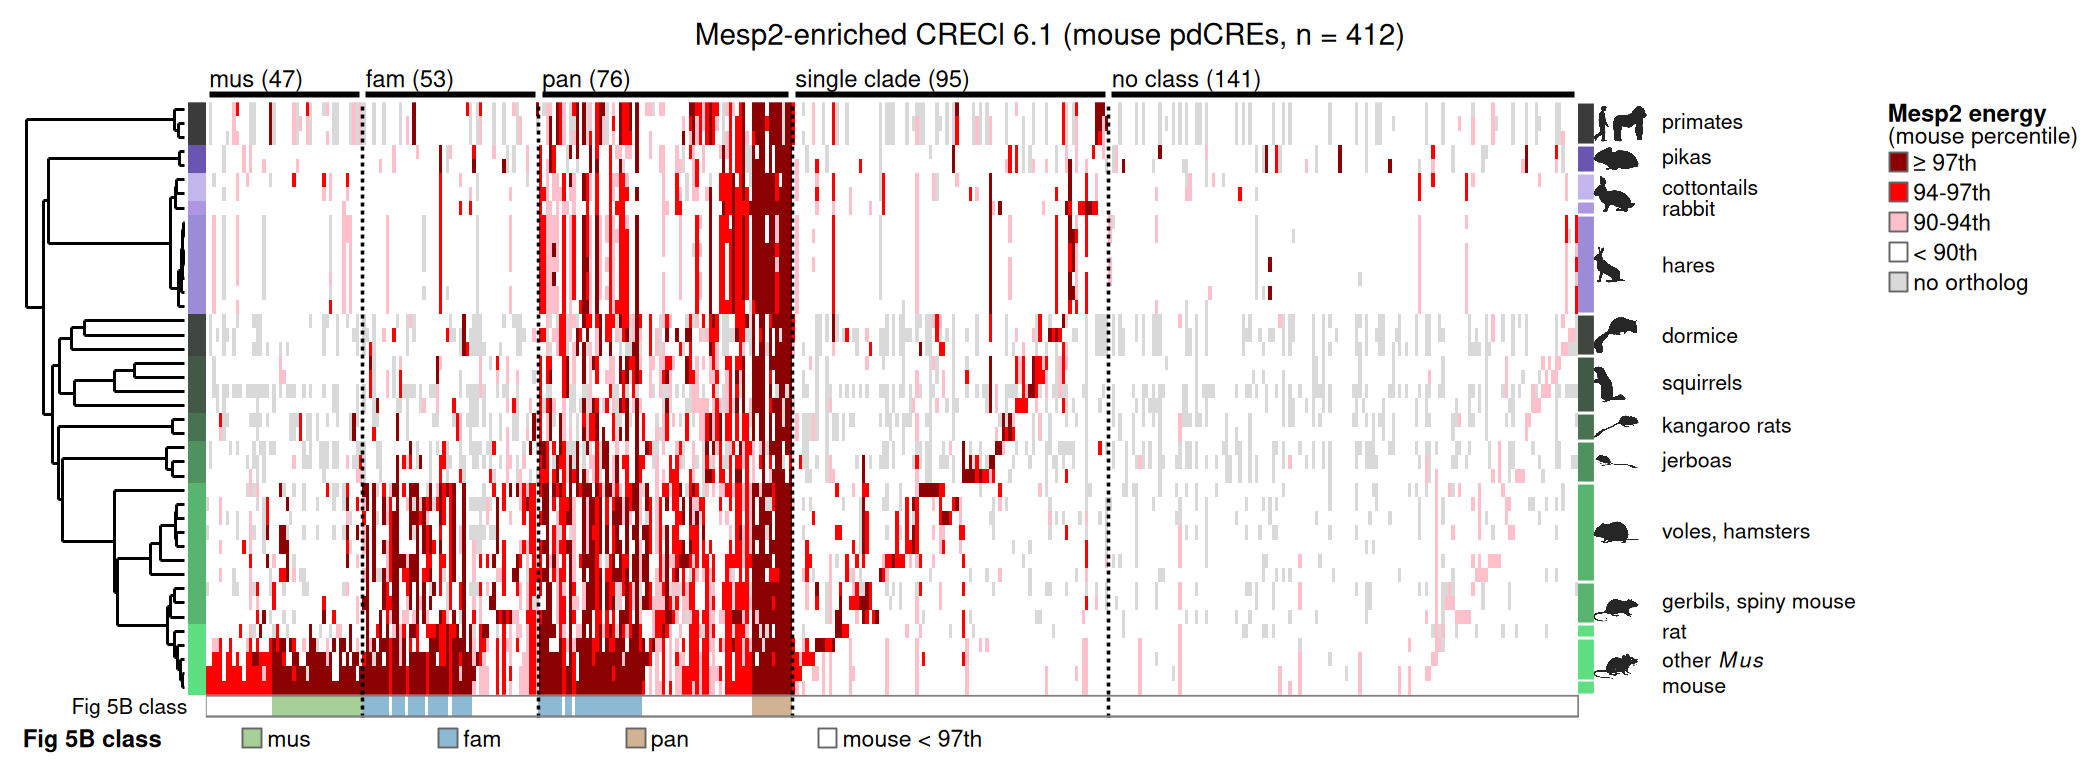

In [18]:
# ---- Fig 5B class row and its key ----
pB <- ggplot(cols) + geom_tile(aes(x, 0, fill = fifelse(is.na(evo5b), "white", EVO5B[evo5b])), height = 1) + scale_fill_identity() + vsep() + xs + theme_void() +
	annotate("rect", xmin = 0.5, xmax = NX + 0.5, ymin = -0.5, ymax = 0.5, fill = NA, colour = "grey50", linewidth = 0.2)
pBl <- ggplot() + annotate("text", x = 1, y = 0, label = "Fig 5B class", hjust = 1, size = 5 / .pt, family = SUP_FONT) +
	scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) + theme_void() + coord_cartesian(clip = "off")
HW_IN <- 7 - 2 * 5.5 / 72 - 0.55 - 0.06 - LW_IN - KW_IN
cpi <- NX / HW_IN
K5 <- data.table(k = c("mus", "fam", "pan", "mouse < 97th"), f = c(unname(EVO5B), "white"), home = c("I", "II", "III", NA))
K5[, w := 0.083 + strw(k, 5.4)][, lw := cumsum(c(0, w[-.N]))]
bc <- gb[match(K5$home[1:3], grp), ((x0 + x1) / 2 - 0.5) / cpi]
ag <- coef(lm(y ~ i, data.frame(y = bc - K5$lw[1:3] - K5$w[1:3] / 2, i = 0:2)))
K5[, left := max(ag[[1]], 0) + lw + (seq_len(.N) - 1) * max(ag[[2]], 0.1)]
pK <- ggplot(K5) + geom_point(aes(0.5 + (left + 0.033) * cpi, 0, fill = f), shape = 22, size = 2.2, colour = "grey40", stroke = 0.25) +
	geom_text(aes(0.5 + (left + 0.083) * cpi, 0, label = k), hjust = 0, size = 5.4 / .pt, family = SUP_FONT) + scale_fill_identity() +
	xs + scale_y_continuous(limits = c(-0.5, 0.5)) + theme_void() + coord_cartesian(clip = "off")
pKt <- ggplot() + annotate("text", x = 0, y = 0, label = "Fig 5B class", hjust = 0, size = 5.6 / .pt, family = SUP_FONT, fontface = "bold") +
	scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) + scale_y_continuous(limits = c(-0.5, 0.5)) + theme_void() + coord_cartesian(clip = "off")
p <- wrap_plots(G = pG, T = pT, S = pS, H = hM, L = pL, E = pE, b = pBl, B = pB, k = pKt, K = pK, design = "
##G##
TSHLE
b#B##
k#K##", widths = unit(c(0.55, 0.06, 1, LW_IN, KW_IN), c("in", "in", "null", "in", "in")), heights = unit(c(HDR_IN, 1, 0.075, 0.14), c("in", "null", "in", "in"))) +
	plot_annotation(title = sprintf("Mesp2-enriched CRECl %s (mouse pdCREs, n = %d)", CRECL_LAB, NX),
		theme = theme(plot.title = element_text(size = 7, hjust = 0.5, family = SUP_FONT, margin = margin(0, 0, 1, 0))))
options(repr.plot.width = 7.0, repr.plot.height = BLK_IN + HDR_IN + 0.075 + 0.14 + 0.26, repr.plot.res = 300)
print(p)